# Café Data Analysis
On this notebook we will be analysing the data collected by a Café over a period of a year.


## Part 1 - EDA

### Step 1 - Setup and Questions
Our task is to explore the data, identify intersting patterns and develop insights to help the business improve its performance, but what does this mean?

#### Immediate questions we would like to see answered
- What are the most sold products in total
- What is the income in total
- What are the most sold products per month
- What are the most sold products per week (including day / histogram)
- What products are usually bought together (see per day, per week, per month)
- What are the most sold products per quartile (each 3 months or per season)
- Do products with discount end up giving more profit?


In [16]:
# Libraries
import sys
!{sys.executable} -m pip install numpy pandas seaborn matplotlib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [17]:
# Variables

### Step 2 - Basic Inspection
A first look at the raw data: its shape, column types, unique values and summary statistics.

In [18]:
# Import and inspect
df_original = pd.read_csv('cafe.csv', delimiter=';', encoding='latin-1') # Had to add encoding, donno why tho
df_original.head()

,Date,Bill Number,Item Desc,Time,Quantity,Rate,Tax,Discount,Total,Category
0,1-Apr-10,G0470115,QUA MINERAL WATER(1000ML),13:15:11,1,50,"11,88",0,"61,88",BEVERAGE
1,1-Apr-10,G0470115,MONSOON MALABAR (AULAIT),13:15:11,1,100,"23,75",0,"123,75",BEVERAGE
2,1-Apr-10,G0470116,MASALA CHAI CUTTING,13:17:35,1,40,"9,5",0,"49,5",BEVERAGE
3,1-Apr-10,G0470117,QUA MINERAL WATER(1000ML),13:19:55,1,50,"11,88",0,"61,88",BEVERAGE
4,1-Apr-10,G0470283,MOROCCAN MINT TEA,01:20:18,1,45,"10,69",0,"55,69",BEVERAGE


In [19]:
df_original.shape

(145830, 10)

The dataset contains 145_830 rows and 10 columns.

In [20]:
df_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 145830 entries, 0 to 145829
Data columns (total 10 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   Date          145830 non-null  str  
 1   Bill Number   145830 non-null  str  
 2   Item Desc     145830 non-null  str  
 3   Time          145830 non-null  str  
 4   Quantity      145830 non-null  int64
 5   Rate          145830 non-null  str  
 6   Tax           145830 non-null  str  
 7   Discount      145830 non-null  str  
 8   Total         145830 non-null  str  
 9   Category      145830 non-null  str  
dtypes: int64(1), str(9)
memory usage: 11.1 MB


Here we noticed that the rate, tax, discount and total were strings instead of floats (because it's money) and that the time is also string and not Datetime.

Another thing is that there is a column called category which can be used to categorize the data.

In [21]:
df_original.nunique()

Date              365
Bill Number     69982
Item Desc         580
Time            36200
Quantity           20
Rate              134
Tax               445
Discount          111
Total             470
Category            9
dtype: int64

This shows us the 365 dates (days) and 9 different categories.

In [22]:
df_original.describe()

,Quantity
count,145830.000000
mean,1.121299
std,0.477237
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,30.000000


Describe only shows Quantity, since like mentioned before, columns that should be floats, aren't. This step will be repeated later.

These columns will be transformed into the right type in the data cleaning step.

### Step 3 - Data Cleaning and Preparation
Before analysing the data we clean it: check for missing values, convert columns to the right types and detect duplicates.

From this point onwards we save a copy of the dataset so we won't touch the raw data.

In [23]:
# Save a copy of the dataset to work with instead of the raw data.
df_copy = df_original.copy()
df_copy.to_csv("data_copy.csv", index=False)

#### Missing values

Next we decided to see if there are any missing values and think on how to handle them

In [24]:
df_copy.isnull().sum()

Date            0
Bill Number     0
Item Desc       0
Time            0
Quantity        0
Rate            0
Tax             0
Discount        0
Total           0
Category        0
dtype: int64

The dataset doesn't contain any missing values, this step can be safely skipped.

#### Type conversion

The columns that must have it's type changed aren't in the good format, the numbers have a ',' instead of '.' which is how python read floats. The next cell fixes this.

In [25]:
# Type conversion
float_cols = ["Rate", "Tax", "Discount", "Total"]
for col in float_cols:
    df_copy[col] = pd.to_numeric(
        df_copy[col].str.replace(',', '.', regex=False),
        errors='coerce'
    )

df_copy["Date"] = df_copy["Date"].astype('datetime64[ns]')


In [26]:
df_copy.describe()

,Date,Quantity,Rate,Tax,Discount,Total
count,145830,145830.000000,145830.000000,145830.000000,145830.000000,145830.000000
mean,2010-10-04 15:52:45.126516992,1.121299,161.782259,48.929061,0.095079,224.959852
min,2010-04-01 00:00:00,1.000000,0.010000,0.000000,0.000000,0.010000
25%,2010-07-10 00:00:00,1.000000,95.000000,22.560000,0.000000,117.560000
50%,2010-10-07 00:00:00,1.000000,125.000000,32.060000,0.000000,167.060000
75%,2011-01-01 00:00:00,1.000000,225.000000,72.000000,0.000000,315.000000
max,2011-03-31 00:00:00,30.000000,2100.000000,2731.250000,825.000000,14231.250000
std,NaN,0.477237,102.244631,40.272851,3.720735,164.960776


Something interesting that popped to me immediately is how the min for Rate (how much something costs before tax) is 0.01 cents and the max is 2100 euros, this seems highly suspicious and flagged for later exploration, but for now let's continue exploring

#### Duplicate detection
TODO: check for duplicate rows and decide how to handle them.

In [27]:
print(f"Number of duplicate rows: {df_copy.duplicated().sum()}")
all_dupes = df_copy[df_copy.duplicated(keep=False)]

all_dupes_sorted = all_dupes.sort_values(by=list(df_copy.columns))
all_dupes_sorted

Number of duplicate rows: 680


,Date,Bill Number,Item Desc,Time,Quantity,Rate,Tax,Discount,Total,Category
197,2010-04-01,G0470211,B.M.T. PANINI,19:42:27,1,105.0,24.94,0.0,129.94,FOOD
198,2010-04-01,G0470211,B.M.T. PANINI,19:42:27,1,105.0,24.94,0.0,129.94,FOOD
199,2010-04-01,G0470211,B.M.T. PANINI,19:42:27,1,105.0,24.94,0.0,129.94,FOOD
4472,2010-04-01,G0470223,ADD ON S,20:33:30,1,15.0,3.56,0.0,18.56,MISC
4473,2010-04-01,G0470223,ADD ON S,20:33:30,1,15.0,3.56,0.0,18.56,MISC
...,...,...,...,...,...,...,...,...,...,...
138712,2011-03-30,G0533709,MEZE PLATTER,22:19:39,1,150.0,35.63,0.0,185.63,FOOD
138725,2011-03-30,G0533714,MEZE PLATTER,22:32:43,1,150.0,35.63,0.0,185.63,FOOD
138726,2011-03-30,G0533714,MEZE PLATTER,22:32:43,1,150.0,35.63,0.0,185.63,FOOD
143213,2011-03-31,G0533751,SUNNY SIDEUP + BEVERAGE,11:45:56,1,99.0,23.51,0.0,122.51,FOOD


#### Aggregating by order
We assumed that sometimes the waiter entered the same item several times in one bill (e.g. 3 x "panini x1" instead of "panini x3"). Here we merge those rows directly in `df_copy`, summing quantity and money, so each item appears once per order.

We also build `df_orders`: one row per order (bill), with the items bought, the total quantity and the money columns summed.

In [28]:
# Merge repeated rows of the same item in the same order into one row
# e.g. 3 rows of "panini x1" in one bill -> 1 row of "panini x3"
df_copy.columns = df_copy.columns.str.strip()          # "Bill Number " has a trailing space
df_copy["Item Desc"] = df_copy["Item Desc"].str.strip()

rows_before = len(df_copy)
df_copy = (
    df_copy.groupby(["Date", "Bill Number", "Item Desc", "Time", "Category"], as_index=False, sort=False)
    .agg(Quantity=("Quantity", "sum"), Rate=("Rate", "first"),
         Tax=("Tax", "sum"), Discount=("Discount", "sum"), Total=("Total", "sum"))
    [["Date", "Bill Number", "Item Desc", "Time", "Quantity", "Rate", "Tax", "Discount", "Total", "Category"]]
)
print(f"Rows: {rows_before} -> {len(df_copy)} ({rows_before - len(df_copy)} rows merged)")

# One row per order (bill)
df_orders = (
    df_copy.groupby(["Bill Number", "Date", "Time"], as_index=False)
    .agg(Items=("Item Desc", lambda s: ", ".join(s)),
         Unique_Items=("Item Desc", "nunique"),
         Quantity=("Quantity", "sum"),
         Tax=("Tax", "sum"), Discount=("Discount", "sum"), Total=("Total", "sum"))
)
df_copy[df_copy["Bill Number"] == "G0470211"]

Rows: 145830 -> 145052 (778 rows merged)


,Date,Bill Number,Item Desc,Time,Quantity,Rate,Tax,Discount,Total,Category
197,2010-04-01,G0470211,B.M.T. PANINI,19:42:27,3,105.0,74.82,0.0,389.82,FOOD
313,2010-04-01,G0470211,SAMBUCA,19:42:27,1,350.0,112.00,0.0,462.00,TOBACCO
314,2010-04-01,G0470211,CALCUTTA MINT,19:42:27,1,350.0,112.00,0.0,462.00,TOBACCO


### Step 4 - Descriptive Statistics

Here we summarise the data with numbers before looking at trends: the headline figures of the business, the centre and spread of the main variables, the shape of their distributions and the best-selling products.

We look at the data on three levels:
- **Line** (`df_copy`): one item in one order
- **Order** (`df_orders`): one bill, i.e. what a customer spends in one visit
- **Day**: the total revenue of each day

#### Overview of the business

In [29]:
# Headline figures for the whole year
n_days = df_copy["Date"].nunique()
total_revenue = df_copy["Total"].sum()

overview = pd.Series({
    "Total revenue (incl. tax)": total_revenue,
    "Total tax": df_copy["Tax"].sum(),
    "Total discount given": df_copy["Discount"].sum(),
    "Number of orders": len(df_orders),
    "Items sold": df_copy["Quantity"].sum(),
    "Unique products": df_copy["Item Desc"].nunique(),
    "Days in the data": n_days,
    "Average revenue per day": total_revenue / n_days,
    "Average orders per day": len(df_orders) / n_days,
})
overview.map("{:,.2f}".format).to_frame("Value")

,Value
Total revenue (incl. tax),"32,805,895.27"
Total tax,"7,135,324.90"
Total discount given,"13,865.38"
Number of orders,"69,982.00"
Items sold,"163,519.00"
Unique products,580.00
Days in the data,365.00
Average revenue per day,"89,879.17"
Average orders per day,191.73


This answers one of our questions: in one year the café made **32,805,895.27 moneys** in total, from 69,982 orders, which is around 90 thousand moneys per day.

#### Measures of center and spread

For each variable we calculate:
- **Centre**: mean, median and mode
- **Spread**: standard deviation, variance, range and IQR (Q3 - Q1)
- **Skewness**: how lopsided the distribution is (0 = symmetric, > 0 = long tail to the right)

In [32]:
def summary_stats(s):
    """Measures of centre and spread of a numeric series."""
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({
        "mean": s.mean(),
        "median": s.median(),
        "mode": s.mode().iloc[0],
        "std": s.std(),
        "variance": s.var(),
        "min": s.min(),
        "max": s.max(),
        "range": s.max() - s.min(),
        "Q1": q1,
        "Q3": q3,
        "IQR": q3 - q1,
        "skewness": s.skew(),
    })

daily_revenue = df_copy.groupby("Date")["Total"].sum()

stats = pd.DataFrame({
    "Item price (Rate)": summary_stats(df_copy["Rate"]),
    "Quantity": summary_stats(df_copy["Quantity"]),
    "Total": summary_stats(df_copy["Total"]),
    "Order total": summary_stats(df_orders["Total"]),
    "Items per order": summary_stats(df_orders["Quantity"]),
    "Daily revenue": summary_stats(daily_revenue),
}).round(2)
stats.T

,mean,median,mode,std,variance,min,max,range,Q1,Q3,IQR,skewness
Item price (Rate),161.75,125.00,245.00,102.23,1.045077e+04,0.01,2100.00,2099.99,95.00,225.00,130.00,1.57
Quantity,1.13,1.00,1.00,0.49,2.400000e-01,1.00,32.00,31.00,1.00,1.00,0.00,9.95
Total,226.17,167.06,323.40,166.97,2.787731e+04,0.01,14231.25,14231.24,117.56,315.00,197.44,7.11
Order total,468.78,391.46,297.00,348.42,1.213992e+05,1.26,14231.25,14229.99,272.25,594.00,321.75,4.37
Items per order,2.34,2.00,1.00,1.80,3.240000e+00,1.00,64.00,63.00,1.00,3.00,2.00,4.24
Daily revenue,89879.17,87034.64,47176.66,18557.71,3.443887e+08,47176.66,249995.13,202818.47,78232.06,99192.94,20960.88,2.22


Observations:
- **Every variable is right-skewed** (mean > median, positive skewness): most values are small, with a long tail of large ones.
- **A typical order** has 2 items and costs around 390 moneys (median). The mean (~470) is pulled up by a few very large bills, so the median is the better "typical" value here.
- **Most lines have quantity 1** (Q1 = Q3 = 1), people order more items rather than more of the same item.
- **Daily revenue** is the most stable variable (mean and median are close), but the max day (~250k) is almost 3x the median, worth checking which day that was in Step 5.
- The **min Rate of 0.01** flagged earlier shows up again, these lines are probably test entries or free items and should be checked in Step 7.

#### Distribution shapes
Histograms show where most of the values are and boxplots show the outliers. The order total histogram is cut at the 99th percentile so the few very large bills don't squash the rest of the plot (the boxplot still shows them).

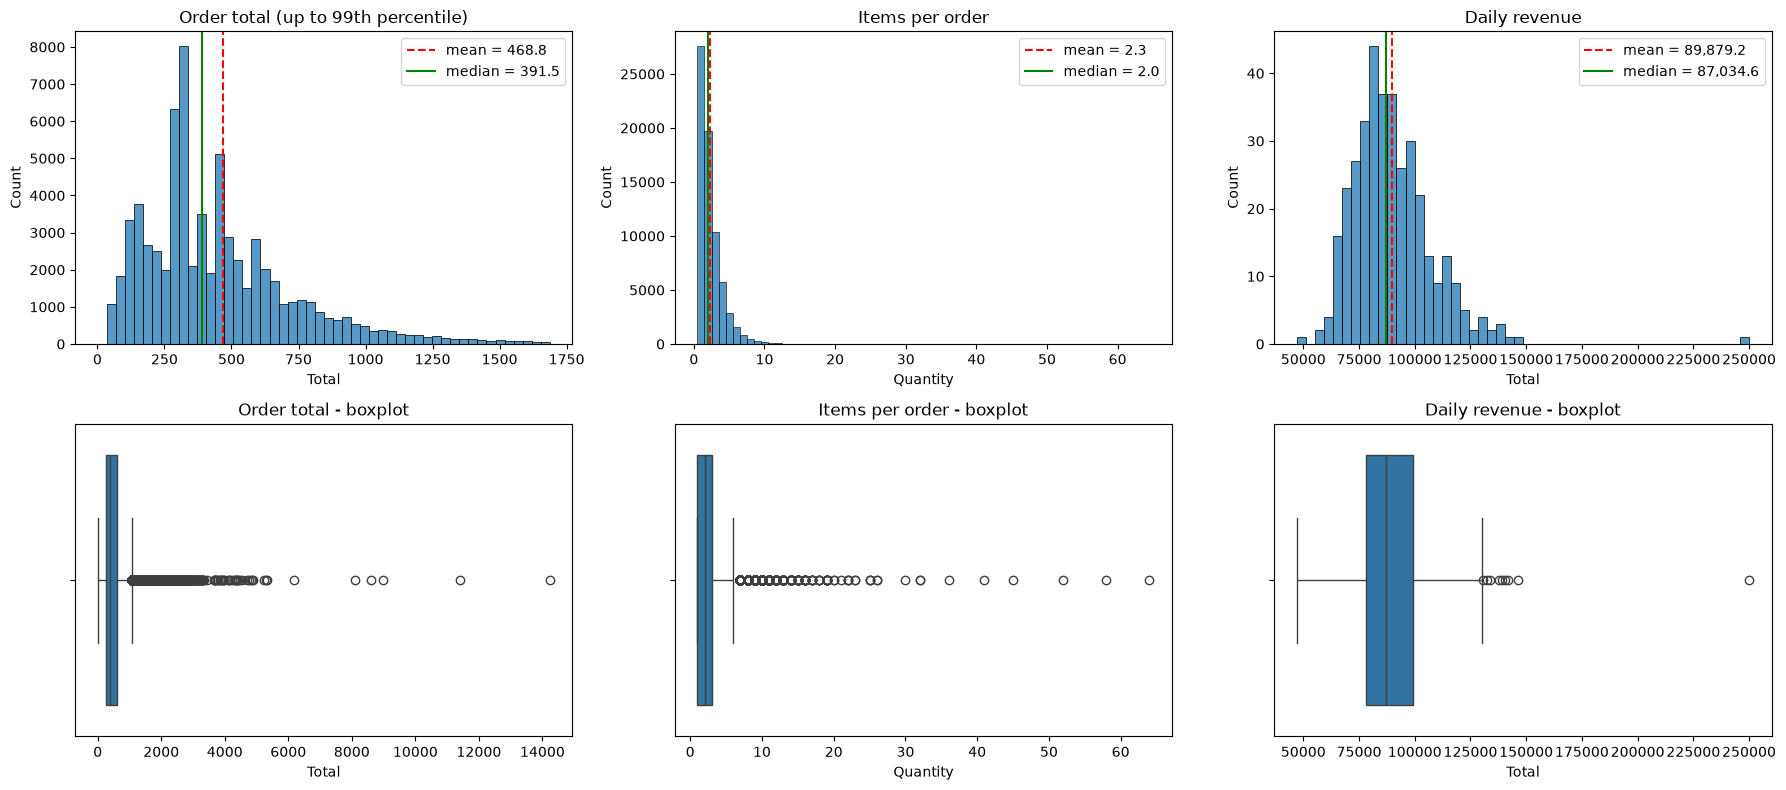

Order total: 3469 high outliers (5.0%)
Items per order: 2051 high outliers (2.9%)
Daily revenue: 9 high outliers (2.5%)


In [33]:
to_plot = {
    "Order total": df_orders["Total"],
    "Items per order": df_orders["Quantity"],
    "Daily revenue": daily_revenue,
}

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for i, (name, s) in enumerate(to_plot.items()):
    # Histogram with mean and median lines
    if name == "Order total":
        sns.histplot(s[s <= s.quantile(0.99)], bins=50, ax=axes[0, i])
        axes[0, i].set_title(f"{name} (up to 99th percentile)")
    elif name == "Items per order":
        sns.histplot(s, discrete=True, ax=axes[0, i])
        axes[0, i].set_title(name)
    else:
        sns.histplot(s, bins=50, ax=axes[0, i])
        axes[0, i].set_title(name)
    axes[0, i].axvline(s.mean(), color="red", linestyle="--", label=f"mean = {s.mean():,.1f}")
    axes[0, i].axvline(s.median(), color="green", label=f"median = {s.median():,.1f}")
    axes[0, i].legend()

    # Boxplot to show the outliers
    sns.boxplot(x=s, ax=axes[1, i])
    axes[1, i].set_title(f"{name} - boxplot")

plt.tight_layout()
plt.show()

# How many values are outliers by the IQR rule (> Q3 + 1.5 * IQR)?
for name, s in to_plot.items():
    q1, q3 = s.quantile([0.25, 0.75])
    n_out = (s > q3 + 1.5 * (q3 - q1)).sum()
    print(f"{name}: {n_out} high outliers ({n_out / len(s):.1%})")

The plots confirm the skewness found above: order totals and items per order pile up on the left with a long tail of large orders, shown as many outlier points in the boxplots. These large orders are most likely groups and are real sales, so we keep them, but it's another reason to prefer the median over the mean when describing a typical customer.

#### Most sold products

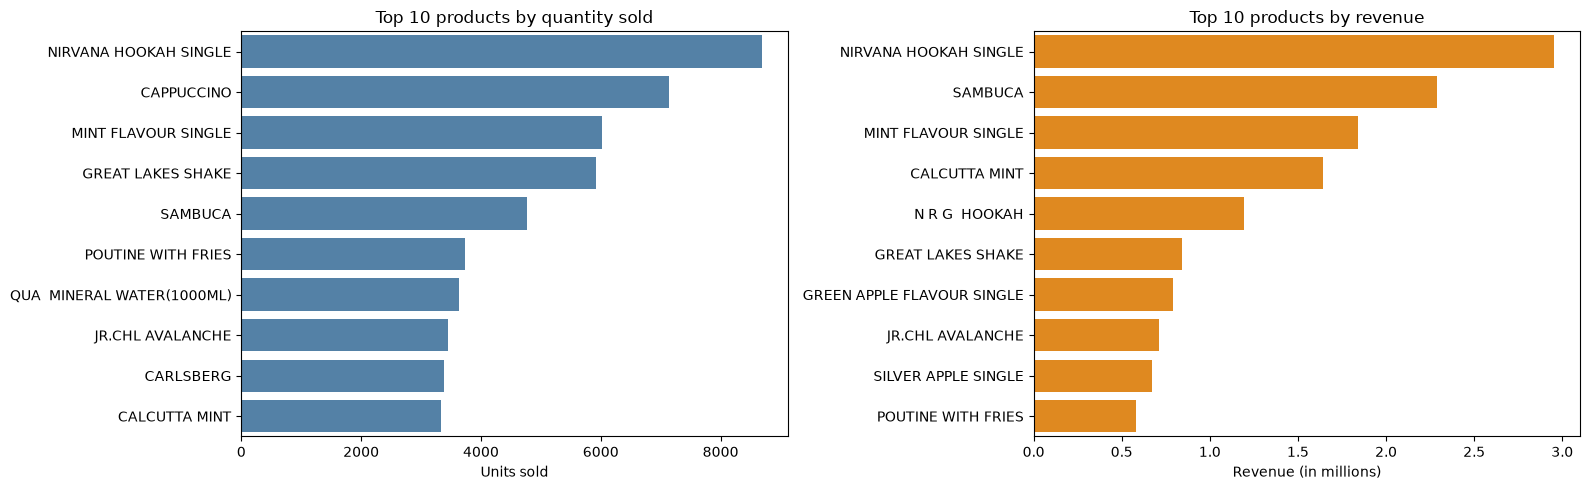

In [34]:
# Top 10 products by quantity sold and by revenue
top_quantity = df_copy.groupby("Item Desc")["Quantity"].sum().nlargest(10)
top_revenue = df_copy.groupby("Item Desc")["Total"].sum().nlargest(10) / 1_000_000

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=top_quantity.values, y=top_quantity.index, ax=axes[0], color="steelblue")
axes[0].set_title("Top 10 products by quantity sold")
axes[0].set_xlabel("Units sold")
axes[0].set_ylabel("")

sns.barplot(x=top_revenue.values, y=top_revenue.index, ax=axes[1], color="darkorange")
axes[1].set_title("Top 10 products by revenue")
axes[1].set_xlabel("Revenue (in millions)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

This answers the question of the most sold products in total. Hookahs are the café's main business: **NIRVANA HOOKAH SINGLE** is number one both in quantity and in revenue. **CAPPUCCINO** is the 2nd most sold item but, being cheap, it doesn't reach the top 5 in revenue, while **SAMBUCA** sells less but is the 2nd biggest earner. Which products drive volume and which drive money will be explored further in Step 6.

### Step 5 - Time Series Analysis and Sales Trend Investigation

In [ ]:
# Revenue per month in chronological order (the data runs from Apr 2010 to Mar 2011,
# so grouping by month number alone would put Jan-Mar 2011 before Apr 2010)
monthly_revenue = df_copy.groupby(df_copy["Date"].dt.to_period("M"))["Total"].sum() / 1_000_000
print("Revenue per month (in millions):")
print(monthly_revenue.round(2))

plt.figure(figsize=(10, 4))
plt.plot(monthly_revenue.index.strftime("%b %y"), monthly_revenue.values, marker="o")
plt.xlabel("Month")
plt.ylabel("Revenue (in millions)")
plt.title("Monthly Revenue")
plt.show()

Very interesting, the sales spiked and than declined after winter with a small jump during the summer months, this could coincide with vacations, but lets keep an open mind and explore further.

### Step 6 - Category Performance and Relationship Discovery

### Step 7 - Offensive Data Preparation & Feature Engineering

### Step 8 - Data Storytelling and Business Synthesis